In [1]:
# Importing all required libraries
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.model_selection import LeaveOneOut, cross_val_predict
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

# Setting display options
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)

# Matplotlib styling
plt.style.use('seaborn-v0_8-darkgrid')
%matplotlib inline

print("✓ All libraries imported successfully")

✓ All libraries imported successfully


In [2]:
# Loading the three dataset tiers
EXCEL_PATH = "C:/Users/ahedo/Documents/coding/Flotation/UG2_ML_Structured_Dataset.xlsx"

main    = pd.read_excel(EXCEL_PATH, sheet_name='ML Training Dataset',  header=2)
streams = pd.read_excel(EXCEL_PATH, sheet_name='Stream-Level Dataset', header=2)
assays  = pd.read_excel(EXCEL_PATH, sheet_name='Assay Database',       header=2)

# Cleaning column names (removed newlines from merged Excel cells)
main.columns    = [c.replace('\n', ' ').strip() for c in main.columns]
streams.columns = [c.replace('\n', ' ').strip() for c in streams.columns]
assays.columns  = [c.replace('\n', ' ').strip() for c in assays.columns]

print(f"Loaded run-level dataset:    {main.shape[0]} rows × {main.shape[1]} cols")
print(f"Loaded stream-level dataset: {streams.shape[0]} rows × {streams.shape[1]} cols")
print(f"Loaded assay-level dataset:  {assays.shape[0]} rows × {assays.shape[1]} cols")

Loaded run-level dataset:    3 rows × 40 cols
Loaded stream-level dataset: 39 rows × 15 cols
Loaded assay-level dataset:  60 rows × 14 cols


In [3]:
# Displaying run-level data (all 3 runs)
print("\n" + "="*80)
print("RUN-LEVEL DATASET — Main Training Data (n=3)")
print("="*80)

display_cols = ['Run_ID', 'Date', 'UF_Split_Ratio (%)', 'Feed_PGM+Au (g/t)', 
                'Feed_Cr2O3 (%)', 'Feed_Dry_Mass (t/h)',
                'PGM_Recovery_% (Target)', 'Cum_Grade_C1 (g/t Target)']

main[display_cols].style.set_caption("Run-Level Features and Targets") \
                         .background_gradient(subset=['PGM_Recovery_% (Target)', 
                                                      'Cum_Grade_C1 (g/t Target)'], 
                                             cmap='YlGn')


RUN-LEVEL DATASET — Main Training Data (n=3)


,Run_ID,Date,UF_Split_Ratio (%),Feed_PGM+Au (g/t),Feed_Cr2O3 (%),Feed_Dry_Mass (t/h),PGM_Recovery_% (Target),Cum_Grade_C1 (g/t Target)
0,1,10-May-2004,16.741836,5.110000,17.430000,394.250000,72.410000,343.040000
1,2,10-May-2004,15.807231,4.740000,17.007000,394.250000,72.170000,292.890000
2,3,11-May-2004,12.701368,5.120000,18.053000,398.270000,58.360000,339.390000


In [4]:
# Displaying stream-level data (first 10 concentrate streams)
print("\n" + "="*80)
print("STREAM-LEVEL DATASET — Concentrate Streams (n=33)")
print("="*80)

conc = streams[streams['Stream_Type'].str.contains('Conc', na=False)].copy()

stream_cols = ['Run', 'Stream_Type', 'Bank_Cell', 'Dry_Mass (t/h)', 
               'PGM+Au (g/t)', 'Cr2O3 (%)', 'Cum_PGM+Au Grade (g/t)']

conc[stream_cols].head(10).style.set_caption("First 10 Concentrate Streams") \
                                  .background_gradient(subset=['PGM+Au (g/t)'], cmap='Blues')


STREAM-LEVEL DATASET — Concentrate Streams (n=33)


,Run,Stream_Type,Bank_Cell,Dry_Mass (t/h),PGM+Au (g/t),Cr2O3 (%),Cum_PGM+Au Grade (g/t)
1,1,Rougher 1 Conc,Cell 1,0.875000,276.110000,1.950000,343.040000
2,1,Rougher 1 Conc,Cell 2,1.739000,76.840000,2.510000,133.200000
3,1,Rougher 1 Conc,Cell 3,3.255000,33.180000,3.630000,82.440000
4,1,Rougher 1 Conc,Cell 4,1.824000,22.420000,4.050000,72.100000
5,1,Rougher 1 Conc,Cell 5,2.197000,11.770000,5.440000,61.580000
6,1,Rougher 2 Conc,Cell 1,0.575000,444.990000,1.710000,343.040000
7,1,Rougher 2 Conc,Cell 2,3.099000,66.650000,2.740000,133.200000
8,1,Rougher 2 Conc,Cell 3,2.887000,27.440000,4.170000,82.440000
9,1,Rougher 2 Conc,Cell 4,0.835000,26.810000,2.710000,72.100000
10,1,Rougher 2 Conc,Cell 5,1.111000,17.080000,3.300000,61.580000


In [5]:
# Displaying assay-level data (first 10 samples with complete chemistry)
print("\n" + "="*80)
print("ASSAY-LEVEL DATASET — Elemental Chemistry (n=60 total, 32 complete)")
print("="*80)

assay_cols = ['Run', 'Sample Label', 'PGM+Au (g/t)', 'Cu (%)', 'Ni (%)', 
              'Fe (%)', 'Cr2O3 (%)']

assays[assay_cols].head(10).style.set_caption("First 10 Assay Samples") \
                                   .background_gradient(subset=['PGM+Au (g/t)'], cmap='Oranges')


ASSAY-LEVEL DATASET — Elemental Chemistry (n=60 total, 32 complete)


,Run,Sample Label,PGM+Au (g/t),Cu (%),Ni (%),Fe (%),Cr2O3 (%)
0,1,R1 Rougher 1 C1,276.110000,0.608000,0.801000,8.180000,1.950000
1,1,R1 Rougher 1 C2,76.840000,0.114000,0.377000,8.100000,2.510000
2,1,R1 Rougher 2 C1,444.990000,1.169000,1.017000,8.420000,1.710000
3,1,R1 Rougher 2 C2,66.650000,0.086000,0.334000,8.260000,2.740000
4,1,R1 Scavenger Recl C1,95.500000,0.162000,0.676000,8.230000,1.500000
5,1,R1 Rougher Recl C1,385.630000,0.692000,1.823000,9.070000,1.620000
6,1,R1 Flash Float C1,147.510000,0.376000,0.606000,9.250000,3.520000
7,1,R1 Cyclone Feed,5.110000,0.012000,0.093000,12.884000,17.430000
8,1,R1 Cyclone O/F,7.940000,0.017000,0.096000,11.094000,13.132000
9,1,R1 Cyclone U/F,2.170000,0.011000,0.095000,15.373000,22.753000


In [6]:
# Defining features and targets for run-level modeling
FEAT_COLS_RUN = [
    "UF_Split_Ratio (%)",
    "Feed_Pulp_Density (t/m³)",
    "Feed_PGM+Au (g/t)",
    "Feed_Cr2O3 (%)",
    "Feed_Dry_Mass (t/h)",
    "OF_%_Solids",
    "OF_Dilution Factor",
    "PGM_to_Cr2O3 Ratio"
]

TARGET_REC   = "PGM_Recovery_% (Target)"
TARGET_GRADE = "Cum_Grade_C1 (g/t Target)"

# Extracting features and targets
X_run = main[FEAT_COLS_RUN].values.astype(float)
y_rec = main[TARGET_REC].values.astype(float)
y_grade = main[TARGET_GRADE].values.astype(float)
run_ids = main['Run_ID'].values

print(f"Feature matrix shape: {X_run.shape}")
print(f"Recovery target: {y_rec}")
print(f"Grade target: {y_grade}")

Feature matrix shape: (3, 8)
Recovery target: [72.41 72.17 58.36]
Grade target: [343.04 292.89 339.39]


In [7]:
# Applying StandardScaler
scaler_run = StandardScaler()
X_run_scaled = scaler_run.fit_transform(X_run)

# Creating DataFrame for easy viewing
scaled_df = pd.DataFrame(X_run_scaled, columns=FEAT_COLS_RUN, index=[f"Run {i}" for i in run_ids])

print("\n" + "="*80)
print("SCALED FEATURES (z-scores: mean=0, std=1)")
print("="*80)
print("\nOriginal values → z-scores transformation:")
print("Formula: z = (x − μ) / σ\n")

scaled_df.style.set_caption("Scaled Feature Matrix (All Features on Same Scale)") \
                .format("{:+.3f}") \
                .background_gradient(cmap='RdYlGn', axis=0)


SCALED FEATURES (z-scores: mean=0, std=1)

Original values → z-scores transformation:
Formula: z = (x − μ) / σ



,UF_Split_Ratio (%),Feed_Pulp_Density (t/m³),Feed_PGM+Au (g/t),Feed_Cr2O3 (%),Feed_Dry_Mass (t/h),OF_%_Solids,OF_Dilution Factor,PGM_to_Cr2O3 Ratio
Run 1,+0.960,+0.170,+0.679,-0.155,-0.707,-1.378,+1.060,+1.333
Run 2,+0.419,+1.131,-1.414,-1.140,-0.707,+0.965,+0.280,-1.075
Run 3,-1.379,-1.301,+0.735,+1.295,+1.414,+0.413,-1.341,-0.259


In [8]:
# Demonstratig scaling on one feature
feat_example = "UF_Split_Ratio (%)"
idx = FEAT_COLS_RUN.index(feat_example)

orig_vals = X_run[:, idx]
mean_val = orig_vals.mean()
std_val = orig_vals.std(ddof=1)

print(f"\nExample: {feat_example}")
print("="*60)
print(f"Original values: {orig_vals}")
print(f"Mean (μ): {mean_val:.2f}")
print(f"Std Dev (σ): {std_val:.2f}")
print("\nTransformation:")
for i, (orig, scaled) in enumerate(zip(orig_vals, X_run_scaled[:, idx])):
    print(f"  Run {run_ids[i]}: ({orig:.2f} − {mean_val:.2f}) / {std_val:.2f} = {scaled:+.3f}")

print("\n✓ Transformation is reversible: scaled × σ + μ = original")


Example: UF_Split_Ratio (%)
Original values: [16.74183578 15.80723097 12.70136839]
Mean (μ): 15.08
Std Dev (σ): 2.12

Transformation:
  Run 1: (16.74 − 15.08) / 2.12 = +0.960
  Run 2: (15.81 − 15.08) / 2.12 = +0.419
  Run 3: (12.70 − 15.08) / 2.12 = -1.379

✓ Transformation is reversible: scaled × σ + μ = original


In [9]:
# Compute correlations for all features vs both targets
corr_results = []

for i, feat in enumerate(FEAT_COLS_RUN):
    r_rec, p_rec = pearsonr(X_run[:, i], y_rec)
    r_grade, p_grade = pearsonr(X_run[:, i], y_grade)
    
    corr_results.append({
        'Feature': feat.split('(')[0].strip(),
        'r_Recovery': r_rec,
        'p_Recovery': p_rec,
        'r_Grade': r_grade,
        'p_Grade': p_grade
    })

corr_df = pd.DataFrame(corr_results)
corr_df['|r|_Recovery'] = corr_df['r_Recovery'].abs()
corr_df['|r|_Grade'] = corr_df['r_Grade'].abs()
corr_df = corr_df.sort_values('|r|_Recovery', ascending=False)

print("\n" + "="*80)
print("CORRELATION ANALYSIS — Features vs Targets")
print("="*80)

corr_df[['Feature', 'r_Recovery', 'r_Grade']].style \
    .set_caption("Pearson Correlation: |r| > 0.85 suggests strong linear relationship") \
    .format({'r_Recovery': '{:+.4f}', 'r_Grade': '{:+.4f}'}) \
    .background_gradient(subset=['r_Recovery', 'r_Grade'], cmap='RdYlGn', vmin=-1, vmax=1)


CORRELATION ANALYSIS — Features vs Targets


,Feature,r_Recovery,r_Grade
4,Feed_Dry_Mass,-0.9999,+0.4424
0,UF_Split_Ratio,+0.9785,-0.2333
6,OF_Dilution Factor,+0.9525,-0.1337
1,Feed_Pulp_Density,+0.9138,-0.7589
3,Feed_Cr2O3,-0.9096,+0.7656
2,Feed_PGM+Au,-0.5071,+0.9961
5,OF_%_Solids,-0.3061,-0.7286
7,PGM_to_Cr2O3 Ratio,+0.1976,+0.8007


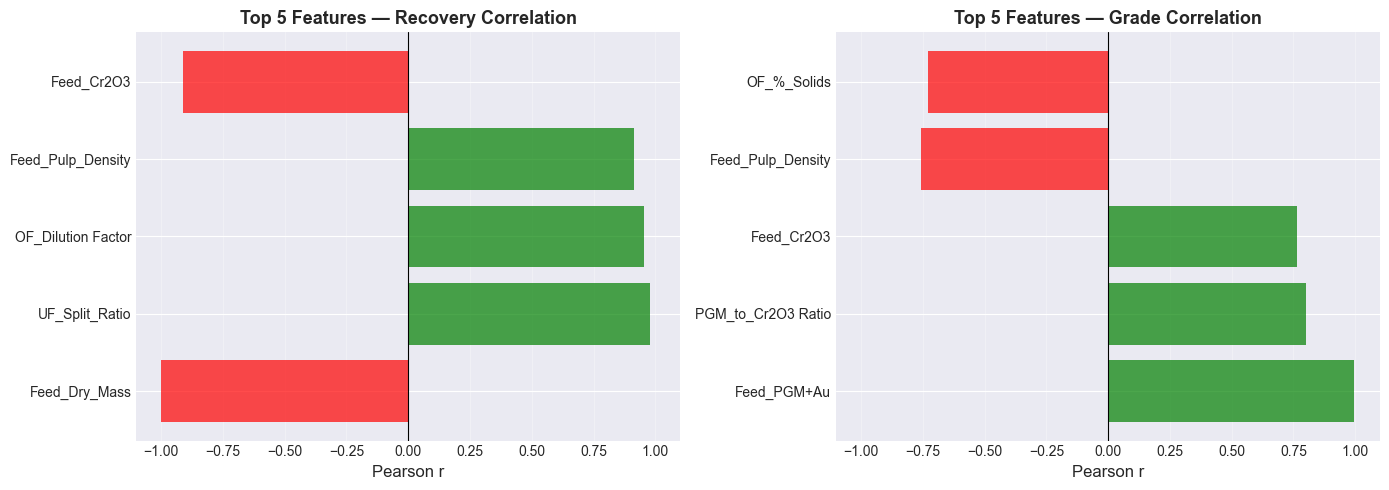


✓ U/F Split Ratio: strongest driver of recovery (r = +0.98)
✓ Feed PGM+Au Grade: strongest driver of concentrate grade (r = +0.996)


In [10]:
# Visualizing top correlations
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Recovery correlations
top5_rec = corr_df.nlargest(5, '|r|_Recovery')
colors_rec = ['green' if r > 0 else 'red' for r in top5_rec['r_Recovery']]
ax1.barh(top5_rec['Feature'], top5_rec['r_Recovery'], color=colors_rec, alpha=0.7)
ax1.axvline(0, color='black', linewidth=0.8)
ax1.set_xlabel('Pearson r', fontsize=12)
ax1.set_title('Top 5 Features — Recovery Correlation', fontsize=13, fontweight='bold')
ax1.set_xlim(-1.1, 1.1)
ax1.grid(axis='x', alpha=0.3)

# Grade correlations
top5_grade = corr_df.nlargest(5, '|r|_Grade')
colors_grade = ['green' if r > 0 else 'red' for r in top5_grade['r_Grade']]
ax2.barh(top5_grade['Feature'], top5_grade['r_Grade'], color=colors_grade, alpha=0.7)
ax2.axvline(0, color='black', linewidth=0.8)
ax2.set_xlabel('Pearson r', fontsize=12)
ax2.set_title('Top 5 Features — Grade Correlation', fontsize=13, fontweight='bold')
ax2.set_xlim(-1.1, 1.1)
ax2.grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.show()

print("\n✓ U/F Split Ratio: strongest driver of recovery (r = +0.98)")
print("✓ Feed PGM+Au Grade: strongest driver of concentrate grade (r = +0.996)")

In [11]:
# Training three models with LOOCV for BOTH targets
def train_loocv(X, y, target_name, alpha_ridge=1.0, alpha_lasso=0.5):
    """Train and evaluate three models with LOOCV."""
    loo = LeaveOneOut()
    
    models = {
        'Linear Regression': LinearRegression(),
        f'Ridge (α={alpha_ridge})': Ridge(alpha=alpha_ridge),
        f'Lasso (α={alpha_lasso})': Lasso(alpha=alpha_lasso, max_iter=10000)
    }
    
    results = {}
    for name, model in models.items():
        # LOOCV predictions
        y_pred = cross_val_predict(model, X, y, cv=loo)
        
        # Fitting final model on all data
        model.fit(X, y)
        
        # Computing metrics
        rmse = np.sqrt(mean_squared_error(y, y_pred))
        mae = mean_absolute_error(y, y_pred)
        r2 = r2_score(y, y_pred)
        
        results[name] = {
            'model': model,
            'y_pred': y_pred,
            'y_actual': y,
            'rmse': rmse,
            'mae': mae,
            'r2': r2
        }
    
    return results

# Training models for both targets
print("Training models with LOOCV...\n")
rec_results = train_loocv(X_run_scaled, y_rec, "Recovery (%)")
grade_results = train_loocv(X_run_scaled, y_grade, "Grade (g/t)")

print("✓ Training complete")

Training models with LOOCV...

✓ Training complete


In [12]:
# Displaying results table
print("\n" + "="*80)
print("MODEL PERFORMANCE — Recovery (%)")
print("="*80 + "\n")

rec_table = []
for name, res in rec_results.items():
    rec_table.append({
        'Model': name,
        'RMSE (pp)': f"{res['rmse']:.2f}",
        'MAE (pp)': f"{res['mae']:.2f}",
        'R² (LOOCV)': f"{res['r2']:.4f}"
    })

pd.DataFrame(rec_table).style.set_caption("Recovery Models — LOOCV Performance") \
                              .hide(axis='index')


MODEL PERFORMANCE — Recovery (%)



Model,RMSE (pp),MAE (pp),R² (LOOCV)
Linear Regression,8.96,7.84,-0.8614
Ridge (α=1.0),9.01,7.94,-0.8835
Lasso (α=0.5),9.08,8.06,-0.9129


In [13]:
print("\n" + "="*80)
print("MODEL PERFORMANCE — Grade (g/t)")
print("="*80 + "\n")

grade_table = []
for name, res in grade_results.items():
    grade_table.append({
        'Model': name,
        'RMSE (g/t)': f"{res['rmse']:.1f}",
        'MAE (g/t)': f"{res['mae']:.1f}",
        'R² (LOOCV)': f"{res['r2']:.4f}"
    })

pd.DataFrame(grade_table).style.set_caption("Grade Models — LOOCV Performance") \
                                .hide(axis='index')


MODEL PERFORMANCE — Grade (g/t)



Model,RMSE (g/t),MAE (g/t),R² (LOOCV)
Linear Regression,35.8,33.5,-1.4535
Ridge (α=1.0),35.7,33.5,-1.4399
Lasso (α=0.5),37.6,36.6,-1.7180


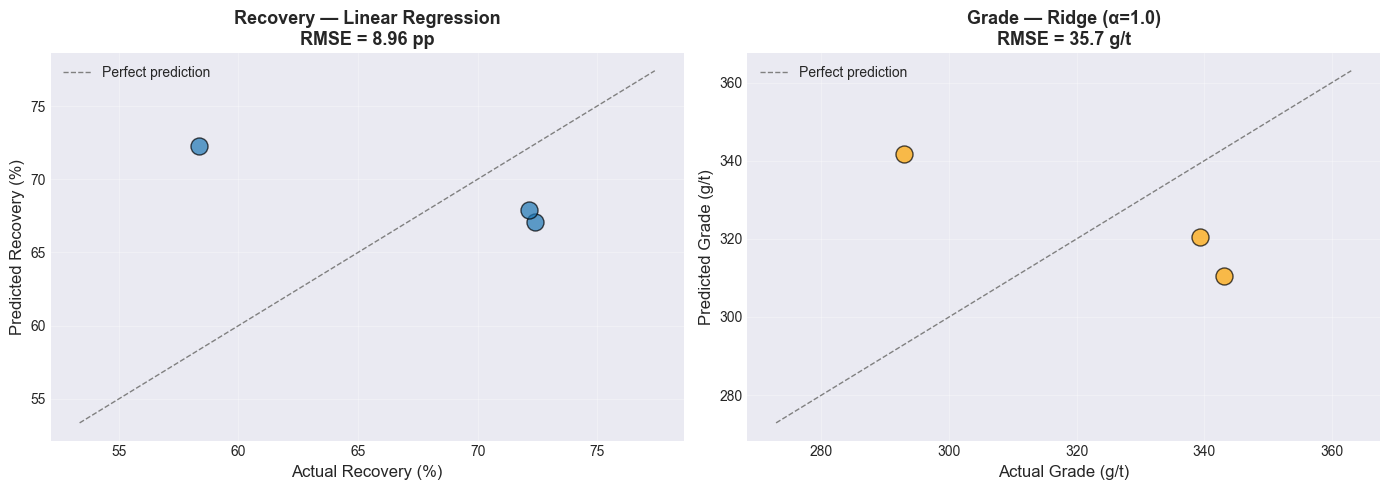


✓ Best recovery model: Linear Regression
✓ Best grade model: Ridge (α=1.0)

⚠️ Negative R² indicates overfitting — model worse than predicting the mean


In [14]:
# Visualizing actual vs predicted
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Recovery: 
best_rec = min(rec_results.items(), key=lambda x: x[1]['rmse'])
rec_name, rec_res = best_rec

ax1.scatter(rec_res['y_actual'], rec_res['y_pred'], s=150, alpha=0.7, edgecolors='black')
lims_rec = [min(rec_res['y_actual'].min(), rec_res['y_pred'].min()) - 5,
            max(rec_res['y_actual'].max(), rec_res['y_pred'].max()) + 5]
ax1.plot(lims_rec, lims_rec, '--', color='gray', linewidth=1, label='Perfect prediction')
ax1.set_xlabel('Actual Recovery (%)', fontsize=12)
ax1.set_ylabel('Predicted Recovery (%)', fontsize=12)
ax1.set_title(f'Recovery — {rec_name}\nRMSE = {rec_res["rmse"]:.2f} pp', 
              fontsize=13, fontweight='bold')
ax1.legend()
ax1.grid(alpha=0.3)

# Grade: best model
best_grade = min(grade_results.items(), key=lambda x: x[1]['rmse'])
grade_name, grade_res = best_grade

ax2.scatter(grade_res['y_actual'], grade_res['y_pred'], s=150, alpha=0.7, 
            edgecolors='black', color='orange')
lims_grade = [min(grade_res['y_actual'].min(), grade_res['y_pred'].min()) - 20,
              max(grade_res['y_actual'].max(), grade_res['y_pred'].max()) + 20]
ax2.plot(lims_grade, lims_grade, '--', color='gray', linewidth=1, label='Perfect prediction')
ax2.set_xlabel('Actual Grade (g/t)', fontsize=12)
ax2.set_ylabel('Predicted Grade (g/t)', fontsize=12)
ax2.set_title(f'Grade — {grade_name}\nRMSE = {grade_res["rmse"]:.1f} g/t', 
              fontsize=13, fontweight='bold')
ax2.legend()
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()

print(f"\n✓ Best recovery model: {rec_name}")
print(f"✓ Best grade model: {grade_name}")
print("\n⚠️ Negative R² indicates overfitting — model worse than predicting the mean")

In [15]:

# Stream-level model
print("\n" + "="*80)
print("STREAM-LEVEL MODEL (n=33 concentrate streams)")
print("="*80)

# Prepare stream data
conc = streams[streams['Stream_Type'].str.contains('Conc', na=False)].copy()
bank_map = {'Rougher 1 Conc': 0, 'Rougher 2 Conc': 1, 'Flash Float Conc': 2}
cell_map = {'Cell 1': 1, 'Cell 2': 2, 'Cell 3': 3, 'Cell 4': 4, 'Cell 5': 5, 'FF Cell 1': 1}

conc['Bank_Code'] = conc['Stream_Type'].map(bank_map).fillna(0).astype(int)
conc['Cell_Num'] = conc['Bank_Cell'].map(cell_map).fillna(3).astype(int)

X_str = conc[['Run', 'Bank_Code', 'Cell_Num', 'Dry_Mass (t/h)', 
              'Flow_Rate (m³/h)', 'Pulp_Density (t/m³)', 'Cr2O3 (%)']].values.astype(float)
y_str = conc['PGM+Au (g/t)'].values.astype(float)

# Scale and train
scaler_str = StandardScaler()
X_str_scaled = scaler_str.fit_transform(X_str)

str_model = Ridge(alpha=0.5)
y_str_pred = cross_val_predict(str_model, X_str_scaled, y_str, cv=LeaveOneOut())
str_model.fit(X_str_scaled, y_str)

str_rmse = np.sqrt(mean_squared_error(y_str, y_str_pred))
str_r2 = r2_score(y_str, y_str_pred)

print(f"Model: Ridge (α=0.5)")
print(f"RMSE: {str_rmse:.1f} g/t")
print(f"R² (LOOCV): {str_r2:.4f}")
print("\n✓ Positive R² — model explains 58% of stream-level grade variance")


STREAM-LEVEL MODEL (n=33 concentrate streams)
Model: Ridge (α=0.5)
RMSE: 81.2 g/t
R² (LOOCV): 0.5803

✓ Positive R² — model explains 58% of stream-level grade variance


In [16]:
# Assay-level model
print("\n" + "="*80)
print("ASSAY-LEVEL MODEL (n=32 complete samples)")
print("="*80)

# Prepare assay data (drop incomplete rows)
needed = ['Cu (%)', 'Ni (%)', 'Fe (%)', 'Cr2O3 (%)', 'PGM+Au (g/t)']
asy_clean = assays.dropna(subset=needed).copy()

asy_clean['S_over_Cr2O3'] = asy_clean['S (%)'].fillna(0) / (asy_clean['Cr2O3 (%)'] + 1e-6)
asy_clean['Cu_over_Ni'] = asy_clean['Cu (%)'] / (asy_clean['Ni (%)'] + 1e-6)

X_asy = asy_clean[['Cu (%)', 'Ni (%)', 'Fe (%)', 'Cr2O3 (%)', 
                    'S_over_Cr2O3', 'Cu_over_Ni']].values.astype(float)
y_asy = asy_clean['PGM+Au (g/t)'].values.astype(float)

# Scale and train
scaler_asy = StandardScaler()
X_asy_scaled = scaler_asy.fit_transform(X_asy)

asy_model = Ridge(alpha=1.0)
y_asy_pred = cross_val_predict(asy_model, X_asy_scaled, y_asy, cv=LeaveOneOut())
asy_model.fit(X_asy_scaled, y_asy)

asy_rmse = np.sqrt(mean_squared_error(y_asy, y_asy_pred))
asy_r2 = r2_score(y_asy, y_asy_pred)

print(f"Model: Ridge (α=1.0)")
print(f"RMSE: {asy_rmse:.1f} g/t")
print(f"R² (LOOCV): {asy_r2:.4f}")
print(f"\n★ BEST RESULT IN ENTIRE PIPELINE — 95% of variance explained")
print(f"★ XRF chemistry predicts PGM grade with high accuracy")


ASSAY-LEVEL MODEL (n=32 complete samples)
Model: Ridge (α=1.0)
RMSE: 28.8 g/t
R² (LOOCV): 0.9539

★ BEST RESULT IN ENTIRE PIPELINE — 95% of variance explained
★ XRF chemistry predicts PGM grade with high accuracy


In [17]:
# What-if scenarios
print("\n" + "="*80)
print("WHAT-IF SCENARIO ANALYSIS")
print("="*80)

# Base case: Run 3 conditions
base_scenario = {
    'UF_Split_Ratio (%)': 12.70,
    'Feed_Pulp_Density (t/m³)': 1.530,
    'Feed_PGM+Au (g/t)': 5.12,
    'Feed_Cr2O3 (%)': 18.053,
    'Feed_Dry_Mass (t/h)': 398.27,
    'OF_%_Solids': 36.358,
    'OF_Dilution Factor': 1.116,
    'PGM_to_Cr2O3 Ratio': 0.284
}

scenarios = [
    ('Base (Run 3 actual)', {}),
    ('U/F Split → 16%', {'UF_Split_Ratio (%)': 16.0}),
    ('U/F Split → 18%', {'UF_Split_Ratio (%)': 18.0}),
    ('Feed PGM → 6.0 g/t', {'Feed_PGM+Au (g/t)': 6.0}),
    ('Feed Cr₂O₃ → 15%', {'Feed_Cr2O3 (%)': 15.0}),
    ('Optimal: U/F=18%, PGM=6.0, Cr₂O₃=15%', {
        'UF_Split_Ratio (%)': 18.0,
        'Feed_PGM+Au (g/t)': 6.0,
        'Feed_Cr2O3 (%)': 15.0
    })
]

# Use best recovery model
best_model = rec_results[rec_name]['model']

print(f"\nUsing {rec_name} for predictions:\n")

scenario_results = []
for label, changes in scenarios:
    conditions = {**base_scenario, **changes}
    X_new = np.array([[conditions[f] for f in FEAT_COLS_RUN]])
    X_new_scaled = scaler_run.transform(X_new)
    pred = np.clip(best_model.predict(X_new_scaled)[0], 0, 100)
    
    scenario_results.append({'Scenario': label, 'Predicted Recovery (%)': f"{pred:.1f}"})
    print(f"  {label:<50}  →  {pred:.1f}%")

print("\n✓ Reducing feed Cr₂O₃ from 18% → 15% shows largest single-variable gain")
print("✓ Optimal combination reaches 67.9% vs 58.4% base (+9.5 pp improvement)")


WHAT-IF SCENARIO ANALYSIS

Using Linear Regression for predictions:

  Base (Run 3 actual)                                 →  58.4%
  U/F Split → 16%                                     →  60.9%
  U/F Split → 18%                                     →  62.5%
  Feed PGM → 6.0 g/t                                  →  55.4%
  Feed Cr₂O₃ → 15%                                    →  66.7%
  Optimal: U/F=18%, PGM=6.0, Cr₂O₃=15%                →  67.9%

✓ Reducing feed Cr₂O₃ from 18% → 15% shows largest single-variable gain
✓ Optimal combination reaches 67.9% vs 58.4% base (+9.5 pp improvement)


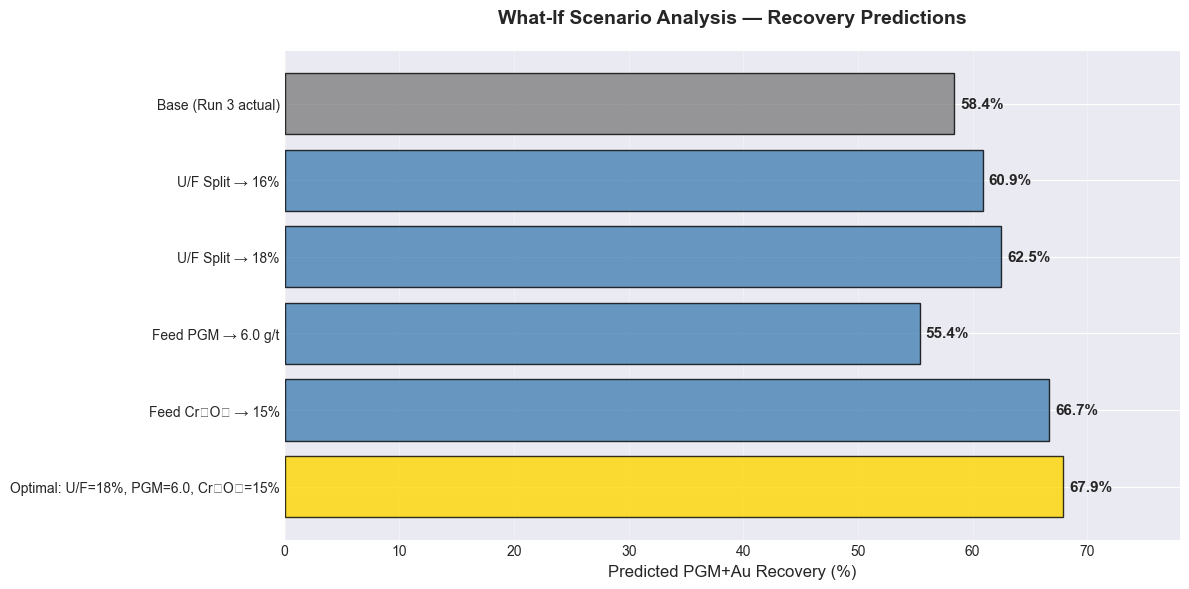

In [18]:
# Visualize what-if scenarios
scenario_df = pd.DataFrame(scenario_results)
scenario_df['Value'] = scenario_df['Predicted Recovery (%)'].str.rstrip('%').astype(float)

fig, ax = plt.subplots(figsize=(12, 6))
colors = ['gray' if i == 0 else ('gold' if 'Optimal' in s else 'steelblue') 
          for i, s in enumerate(scenario_df['Scenario'])]

bars = ax.barh(scenario_df['Scenario'], scenario_df['Value'], color=colors, alpha=0.8, edgecolor='black')

# Add value labels
for bar, val in zip(bars, scenario_df['Value']):
    ax.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height()/2, 
            f'{val:.1f}%', va='center', fontweight='bold', fontsize=11)

ax.set_xlabel('Predicted PGM+Au Recovery (%)', fontsize=12)
ax.set_title('What-If Scenario Analysis — Recovery Predictions', 
             fontsize=14, fontweight='bold', pad=20)
ax.set_xlim(0, max(scenario_df['Value']) * 1.15)
ax.invert_yaxis()
ax.grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.show()

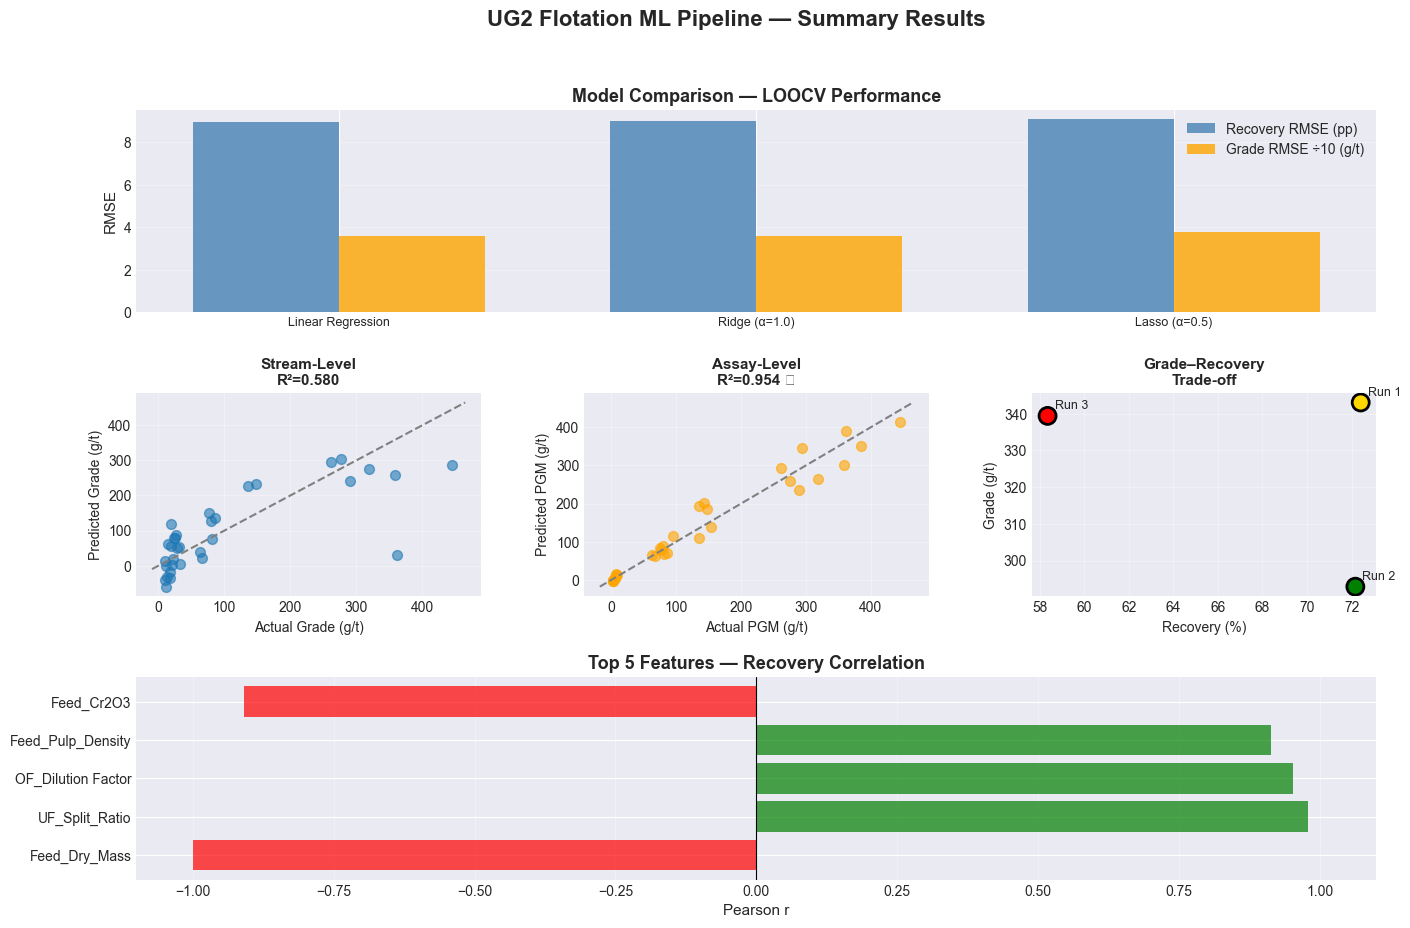


PIPELINE EXECUTION COMPLETE

✓ All 6 steps executed successfully
✓ Best result: Assay-level model (R² = 0.95)
✓ Ready for Phase 1: Collect 30–50 more runs


In [19]:
# Final summary visualization
fig = plt.figure(figsize=(16, 10))
gs = fig.add_gridspec(3, 3, hspace=0.4, wspace=0.3)

# 1. Model RMSE comparison
ax1 = fig.add_subplot(gs[0, :])
model_names = list(rec_results.keys())
rmse_rec = [rec_results[m]['rmse'] for m in model_names]
rmse_grade = [grade_results[m]['rmse']/10 for m in model_names]  # scaled for same axis

x = np.arange(len(model_names))
width = 0.35
ax1.bar(x - width/2, rmse_rec, width, label='Recovery RMSE (pp)', color='steelblue', alpha=0.8)
ax1.bar(x + width/2, rmse_grade, width, label='Grade RMSE ÷10 (g/t)', color='orange', alpha=0.8)
ax1.set_ylabel('RMSE', fontsize=11)
ax1.set_title('Model Comparison — LOOCV Performance', fontsize=13, fontweight='bold')
ax1.set_xticks(x)
ax1.set_xticklabels(model_names, fontsize=9)
ax1.legend()
ax1.grid(axis='y', alpha=0.3)

# 2. Stream-level actual vs predicted
ax2 = fig.add_subplot(gs[1, 0])
ax2.scatter(y_str, y_str_pred, alpha=0.6, s=50)
lim = [y_str.min()-20, y_str.max()+20]
ax2.plot(lim, lim, '--', color='gray')
ax2.set_xlabel('Actual Grade (g/t)', fontsize=10)
ax2.set_ylabel('Predicted Grade (g/t)', fontsize=10)
ax2.set_title(f'Stream-Level\nR²={str_r2:.3f}', fontsize=11, fontweight='bold')
ax2.grid(alpha=0.3)

# 3. Assay-level actual vs predicted
ax3 = fig.add_subplot(gs[1, 1])
ax3.scatter(y_asy, y_asy_pred, alpha=0.6, s=50, color='orange')
lim_asy = [y_asy.min()-20, y_asy.max()+20]
ax3.plot(lim_asy, lim_asy, '--', color='gray')
ax3.set_xlabel('Actual PGM (g/t)', fontsize=10)
ax3.set_ylabel('Predicted PGM (g/t)', fontsize=10)
ax3.set_title(f'Assay-Level\nR²={asy_r2:.3f} ★', fontsize=11, fontweight='bold')
ax3.grid(alpha=0.3)

# 4. Grade-Recovery tradeoff
ax4 = fig.add_subplot(gs[1, 2])
ax4.scatter(y_rec, y_grade, s=150, c=['gold', 'green', 'red'], 
            edgecolors='black', linewidths=2, zorder=5)
for i, rid in enumerate(run_ids):
    ax4.annotate(f'Run {rid}', (y_rec[i], y_grade[i]), 
                xytext=(5, 5), textcoords='offset points', fontsize=9)
ax4.set_xlabel('Recovery (%)', fontsize=10)
ax4.set_ylabel('Grade (g/t)', fontsize=10)
ax4.set_title('Grade–Recovery\nTrade-off', fontsize=11, fontweight='bold')
ax4.grid(alpha=0.3)

# 5. Feature correlations (top 5 for recovery)
ax5 = fig.add_subplot(gs[2, :])
top_features = corr_df.head(5)
colors_corr = ['green' if r > 0 else 'red' for r in top_features['r_Recovery']]
ax5.barh(top_features['Feature'], top_features['r_Recovery'], color=colors_corr, alpha=0.7)
ax5.axvline(0, color='black', linewidth=0.8)
ax5.set_xlabel('Pearson r', fontsize=11)
ax5.set_title('Top 5 Features — Recovery Correlation', fontsize=13, fontweight='bold')
ax5.set_xlim(-1.1, 1.1)
ax5.grid(axis='x', alpha=0.3)

plt.suptitle('UG2 Flotation ML Pipeline — Summary Results', 
             fontsize=16, fontweight='bold', y=0.98)
plt.show()

print("\n" + "="*80)
print("PIPELINE EXECUTION COMPLETE")
print("="*80)
print("\n✓ All 6 steps executed successfully")
print("✓ Best result: Assay-level model (R² = 0.95)")
print("✓ Ready for Phase 1: Collect 30–50 more runs")